# SAMS Fusion — Risk Classification (NORMAL / CAUTION / DANGER)

Train the **Fusion Model**: the final SAMS classifier that combines Vision + Vibration
outputs into a three-class safety-risk decision.

## Run on Google Colab
1. Upload this notebook to [Google Colab](https://colab.research.google.com/) (or open from Drive).
2. Runtime → **Run all** (CPU is enough; no GPU required).
3. Allow **Google Drive** mount when prompted — models/results save under `MyDrive/SAMS/`.
4. Until real experiment logs exist, the notebook auto-generates a rule-guided synthetic fusion dataset.
5. To use real data later, place `fusion_experiment_logs.csv` in `MyDrive/SAMS/datasets/fusion/`.

## Purpose
The Fusion Model does **not** process raw images or raw accelerometer signals.
It receives processed features from:

- **Vision Model** — worker presence, distance, zones, speed, approach, confidence
- **Vibration Model** — machine activity, vibration state, anomaly score

and predicts:

| Index | Class |
|------:|-------|
| 0 | NORMAL |
| 1 | CAUTION |
| 2 | DANGER |

## SAMS ML architecture
```text
Camera                         Accelerometer
   │                                │
   ▼                                ▼
Vision Model                  Vibration Model
   │                                │
   └────────────┬───────────────────┘
                ▼
          Feature Fusion
                │
                ▼
      Random Forest (+ XGB / SVM / MLP)
                │
        ┌───────┼───────┐
        ▼       ▼       ▼
      NORMAL  CAUTION  DANGER
```

## Goals
- Build a fusion feature table (synthetic v1 → replace with real experiment logs later)
- Assign ground-truth risk labels with clear safety rules
- Split by **experimental trial** (no leakage)
- Train **Random Forest** as the primary model
- Compare with XGBoost, SVM, MLP
- Emphasize **DANGER recall**, false-alarm rate, and inference latency
- Save model + metadata for deployment

## Feature set (v1)

| Feature | Source |
|---------|--------|
| `worker_detected` | Vision |
| `worker_distance` | Vision |
| `inside_caution_zone` | Vision |
| `inside_danger_zone` | Vision |
| `worker_speed` | Vision |
| `approaching_machine` | Vision |
| `vision_confidence` | Vision |
| `machine_active` | Vibration / system |
| `vibration_state` | Vibration |
| `vibration_anomaly_score` | Vibration |

## Experiment plan

| # | Approach | Model |
|---|----------|-------|
| 1 | Classical baseline (recommended) | Random Forest |
| 2 | Boosted trees | XGBoost |
| 3 | Margin classifier | SVM (RBF) |
| 4 | Neural net | MLP |

## Pipeline
```text
Vision outputs + Vibration outputs
        → Feature fusion table
        → Trial-holdout split (70 / 15 / 15)
        → RF / XGBoost / SVM / MLP
        → NORMAL / CAUTION / DANGER
        → Compare (DANGER recall first)
```

## Progression
```text
Rule-guided synthetic fusion data → Real synchronized SAMS experiments → Deploy
```


## 0. Colab setup — directories, Drive, packages

In [1]:
# --- Colab environment -------------------------------------------------------
import os
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print("Running in Colab:", IN_COLAB)

SAMS_ROOT = Path("/content/SAMS") if IN_COLAB else Path("./SAMS_runtime")
for p in [
    SAMS_ROOT / "datasets" / "fusion",
    SAMS_ROOT / "models",
    SAMS_ROOT / "notebooks",
    SAMS_ROOT / "results",
]:
    p.mkdir(parents=True, exist_ok=True)

print("SAMS_ROOT:", SAMS_ROOT.resolve())


Running in Colab: True
SAMS_ROOT: /content/SAMS


In [2]:
# --- Mount Google Drive (persist trained models / results) -------------------
DRIVE_ROOT = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    # Local mirror (matches vision / vibration notebooks)
    DRIVE_ROOT = Path("./SAMS_drive_mirror")

for p in [
    DRIVE_ROOT / "models" / "fusion",
    DRIVE_ROOT / "experiments",
    DRIVE_ROOT / "results" / "fusion",
    DRIVE_ROOT / "datasets" / "fusion",
]:
    p.mkdir(parents=True, exist_ok=True)

MODELS_DIR = DRIVE_ROOT / "models" / "fusion"
RESULTS_DIR = DRIVE_ROOT / "results" / "fusion"
EXPERIMENTS_DIR = DRIVE_ROOT / "experiments"
DATA_DIR = DRIVE_ROOT / "datasets" / "fusion"

# Prefer repo datasets/fusion when running from the SAMS project root
repo_data = Path("datasets/fusion")
if (not IN_COLAB) and (repo_data.exists() or Path("notebooks").exists()):
    repo_data.mkdir(parents=True, exist_ok=True)
    DATA_DIR = repo_data

print("DRIVE_ROOT:", DRIVE_ROOT.resolve())
print("MODELS_DIR:", MODELS_DIR.resolve())
print("RESULTS_DIR:", RESULTS_DIR.resolve())
print("DATA_DIR:   ", DATA_DIR.resolve())


Mounted at /content/drive
DRIVE_ROOT: /content/drive/MyDrive/SAMS
MODELS_DIR: /content/drive/MyDrive/SAMS/models/fusion
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/fusion
DATA_DIR:    /content/drive/MyDrive/SAMS/datasets/fusion


In [3]:
# --- Install dependencies ----------------------------------------------------
# Colab already ships numpy / pandas / matplotlib; we ensure sklearn + xgboost.
import subprocess
import sys

pkgs = [
    "scikit-learn",
    "xgboost",
    "seaborn",
    "tqdm",
    "joblib",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    print("Packages installed:", ", ".join(pkgs))
else:
    print("Skipping pip install outside Colab (use your venv if needed).")
    print("Required:", ", ".join(pkgs))


Packages installed: scikit-learn, xgboost, seaborn, tqdm, joblib


In [4]:
# --- Imports & reproducibility -----------------------------------------------
import gc
import json
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import joblib
try:
    from IPython.display import display
except ImportError:  # plain Python / CI smoke tests
    def display(obj):
        print(obj)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

CLASS_NAMES = ["NORMAL", "CAUTION", "DANGER"]
LABEL_TO_IDX = {"NORMAL": 0, "CAUTION": 1, "DANGER": 2}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}

FEATURE_COLS = [
    "worker_detected",
    "worker_distance",
    "inside_caution_zone",
    "inside_danger_zone",
    "worker_speed",
    "approaching_machine",
    "vision_confidence",
    "machine_active",
    "vibration_state",
    "vibration_anomaly_score",
]

# Zone geometry used by the synthetic generator (metres)
CAUTION_ZONE_M = 2.0
DANGER_ZONE_M = 0.8

print("Classes:", CLASS_NAMES)
print("Features:", FEATURE_COLS)
print(f"Zones: caution ≤ {CAUTION_ZONE_M} m | danger ≤ {DANGER_ZONE_M} m")


Classes: ['NORMAL', 'CAUTION', 'DANGER']
Features: ['worker_detected', 'worker_distance', 'inside_caution_zone', 'inside_danger_zone', 'worker_speed', 'approaching_machine', 'vision_confidence', 'machine_active', 'vibration_state', 'vibration_anomaly_score']
Zones: caution ≤ 2.0 m | danger ≤ 0.8 m


## 1. Build fusion dataset

Real SAMS experiments will later produce timestamp-synchronized Vision + Vibration logs.
Until those exist, this notebook generates a **rule-guided synthetic fusion dataset** that
mirrors the intended feature space and safety labelling logic.

Replace the generator with real experiment CSV once available (`DATA_DIR / "fusion_experiment_logs.csv"`).


In [5]:
def assign_risk_label(row: pd.Series) -> int:
    """Ground-truth risk from fused features (safety rules for labelling / synthetic data).

    Priority: DANGER > CAUTION > NORMAL
    """
    detected = int(row["worker_detected"])
    dist = float(row["worker_distance"])
    caution = int(row["inside_caution_zone"])
    danger = int(row["inside_danger_zone"])
    approaching = int(row["approaching_machine"])
    machine_on = int(row["machine_active"])
    vib_abnormal = int(row["vibration_state"])  # 0=normal, 1=abnormal
    vib_score = float(row["vibration_anomaly_score"])

    # Immediate worker–machine hazard
    if detected and machine_on and danger:
        return LABEL_TO_IDX["DANGER"]
    if detected and machine_on and dist <= DANGER_ZONE_M:
        return LABEL_TO_IDX["DANGER"]
    if detected and machine_on and caution and approaching and dist <= 1.2:
        return LABEL_TO_IDX["DANGER"]

    # Developing / elevated risk
    if detected and machine_on and caution:
        return LABEL_TO_IDX["CAUTION"]
    if detected and machine_on and approaching and dist <= CAUTION_ZONE_M:
        return LABEL_TO_IDX["CAUTION"]
    if machine_on and vib_abnormal and vib_score >= 0.55:
        return LABEL_TO_IDX["CAUTION"]
    if detected and (not machine_on) and danger:
        # Machine off but worker inside danger envelope — still caution
        return LABEL_TO_IDX["CAUTION"]

    return LABEL_TO_IDX["NORMAL"]


def generate_trial_samples(
    trial_id: int,
    scenario: str,
    n_samples: int,
    rng: np.random.Generator,
) -> pd.DataFrame:
    """Simulate one experimental trial as a short time series of fused observations."""
    rows = []

    # Scenario priors control how often each situation appears
    if scenario == "safe_standback":
        base_dist = rng.uniform(2.5, 6.0)
        approach_p, machine_on_p, vib_abn_p = 0.15, 0.85, 0.08
    elif scenario == "caution_approach":
        base_dist = rng.uniform(0.9, 2.2)
        approach_p, machine_on_p, vib_abn_p = 0.75, 0.90, 0.12
    elif scenario == "danger_proximity":
        base_dist = rng.uniform(0.15, 1.0)
        approach_p, machine_on_p, vib_abn_p = 0.85, 0.95, 0.18
    elif scenario == "abnormal_vibration":
        base_dist = rng.uniform(2.0, 5.5)
        approach_p, machine_on_p, vib_abn_p = 0.20, 0.95, 0.85
    elif scenario == "machine_idle":
        base_dist = rng.uniform(0.4, 4.0)
        approach_p, machine_on_p, vib_abn_p = 0.40, 0.10, 0.05
    else:  # mixed
        base_dist = rng.uniform(0.3, 5.5)
        approach_p, machine_on_p, vib_abn_p = 0.45, 0.80, 0.25

    # Random walk in distance over the trial
    dist = base_dist
    for t in range(n_samples):
        worker_detected = int(rng.random() > 0.05)  # occasional miss
        if worker_detected:
            step = rng.normal(0.0, 0.12)
            # Bias toward machine when approaching scenarios
            if scenario in ("caution_approach", "danger_proximity") and rng.random() < 0.6:
                step -= abs(rng.normal(0.05, 0.04))
            dist = float(np.clip(dist + step, 0.05, 8.0))
        else:
            dist = 99.0  # sentinel: no worker

        approaching = int(worker_detected and rng.random() < approach_p and dist < 6.0)
        machine_active = int(rng.random() < machine_on_p)
        vib_state = int(machine_active and rng.random() < vib_abn_p)
        vib_score = float(np.clip(rng.beta(5, 2) if vib_state else rng.beta(2, 8), 0.0, 1.0))
        if not machine_active:
            vib_state, vib_score = 0, float(rng.uniform(0.0, 0.15))

        inside_danger = int(worker_detected and dist <= DANGER_ZONE_M)
        inside_caution = int(worker_detected and dist <= CAUTION_ZONE_M)
        worker_speed = float(np.clip(abs(rng.normal(0.6 if approaching else 0.15, 0.25)), 0.0, 2.5))
        if not worker_detected:
            worker_speed = 0.0
            approaching = 0
            inside_caution = 0
            inside_danger = 0

        vision_confidence = float(np.clip(rng.normal(0.88 if worker_detected else 0.55, 0.08), 0.35, 0.99))

        row = {
            "trial_id": trial_id,
            "scenario": scenario,
            "t": t,
            "timestamp_s": trial_id * 1000 + t * 0.2,  # 5 Hz fusion rate
            "worker_detected": worker_detected,
            "worker_distance": dist if worker_detected else 99.0,
            "inside_caution_zone": inside_caution,
            "inside_danger_zone": inside_danger,
            "worker_speed": worker_speed,
            "approaching_machine": approaching,
            "vision_confidence": vision_confidence,
            "machine_active": machine_active,
            "vibration_state": vib_state,
            "vibration_anomaly_score": vib_score,
        }
        rows.append(row)

    trial_df = pd.DataFrame(rows)
    trial_df["label"] = trial_df.apply(assign_risk_label, axis=1)
    trial_df["label_name"] = trial_df["label"].map(IDX_TO_LABEL)
    return trial_df


def build_fusion_dataset(
    n_trials: int = 60,
    samples_per_trial: int = 40,
    seed: int = SEED,
) -> pd.DataFrame:
    local_rng = np.random.default_rng(seed)
    scenarios = [
        "safe_standback",
        "caution_approach",
        "danger_proximity",
        "abnormal_vibration",
        "machine_idle",
        "mixed",
    ]
    # Balance scenarios across trials
    scenario_cycle = (scenarios * ((n_trials // len(scenarios)) + 1))[:n_trials]
    local_rng.shuffle(scenario_cycle)

    frames = []
    for tid, sc in enumerate(tqdm(scenario_cycle, desc="Generating trials")):
        frames.append(generate_trial_samples(tid, sc, samples_per_trial, local_rng))
    return pd.concat(frames, ignore_index=True)


real_log = DATA_DIR / "fusion_experiment_logs.csv"
if real_log.exists():
    print("Loading real experiment logs:", real_log)
    fusion_df = pd.read_csv(real_log)
    if "label" not in fusion_df.columns and "label_name" in fusion_df.columns:
        fusion_df["label"] = fusion_df["label_name"].map(LABEL_TO_IDX)
    elif "label" not in fusion_df.columns:
        fusion_df["label"] = fusion_df.apply(assign_risk_label, axis=1)
        fusion_df["label_name"] = fusion_df["label"].map(IDX_TO_LABEL)
    DATA_SOURCE = "real_experiment_logs"
else:
    print("No real logs found — generating rule-guided synthetic fusion dataset.")
    fusion_df = build_fusion_dataset(n_trials=60, samples_per_trial=40, seed=SEED)
    DATA_SOURCE = "synthetic_rule_guided"

out_csv = DATA_DIR / "fusion_features_labeled.csv"
fusion_df.to_csv(out_csv, index=False)
print(f"Rows: {len(fusion_df)} | Trials: {fusion_df['trial_id'].nunique()} | Source: {DATA_SOURCE}")
print(fusion_df["label_name"].value_counts().reindex(CLASS_NAMES))
display(fusion_df.head(8))
print("Saved:", out_csv.resolve())


No real logs found — generating rule-guided synthetic fusion dataset.


Generating trials:   0%|          | 0/60 [00:00<?, ?it/s]

Rows: 2400 | Trials: 60 | Source: synthetic_rule_guided
label_name
NORMAL     1779
CAUTION     493
DANGER      128
Name: count, dtype: int64


,trial_id,scenario,t,timestamp_s,worker_detected,worker_distance,inside_caution_zone,inside_danger_zone,worker_speed,approaching_machine,vision_confidence,machine_active,vibration_state,vibration_anomaly_score,label,label_name
0,0,machine_idle,0,0.0,1,3.462820,0,0,0.166895,0,0.903130,0,0,0.029986,0,NORMAL
1,0,machine_idle,1,0.2,1,3.287961,0,0,0.270717,0,0.853209,0,0,0.070664,0,NORMAL
2,0,machine_idle,2,0.4,1,3.358308,0,0,0.133322,0,0.806444,0,0,0.128010,0,NORMAL
3,0,machine_idle,3,0.6,1,3.375399,0,0,0.059237,0,0.849461,0,0,0.025046,0,NORMAL
4,0,machine_idle,4,0.8,1,3.433836,0,0,0.580070,1,0.745013,0,0,0.045227,0,NORMAL
5,0,machine_idle,5,1.0,1,3.275112,0,0,0.083404,0,0.863565,0,0,0.107534,0,NORMAL
6,0,machine_idle,6,1.2,1,3.234428,0,0,0.017627,0,0.898614,0,0,0.113778,0,NORMAL
7,0,machine_idle,7,1.4,1,3.426641,0,0,0.515826,0,0.784899,1,0,0.161420,0,NORMAL


Saved: /content/drive/MyDrive/SAMS/datasets/fusion/fusion_features_labeled.csv


## 2. Exploratory Data Analysis

=== Overview ===
                          count unique           top  freq       mean  \
worker_detected          2400.0    NaN           NaN   NaN    0.94375   
worker_distance          2400.0    NaN           NaN   NaN  11.222521   
inside_caution_zone      2400.0    NaN           NaN   NaN     0.1025   
inside_danger_zone       2400.0    NaN           NaN   NaN       0.05   
worker_speed             2400.0    NaN           NaN   NaN   0.285322   
approaching_machine      2400.0    NaN           NaN   NaN    0.15125   
vision_confidence        2400.0    NaN           NaN   NaN   0.861075   
machine_active           2400.0    NaN           NaN   NaN    0.76625   
vibration_state          2400.0    NaN           NaN   NaN   0.225833   
vibration_anomaly_score  2400.0    NaN           NaN   NaN   0.282281   
label_name                 2400      3        NORMAL  1779        NaN   
scenario                   2400      6  machine_idle   400        NaN   
trial_id                 2400.0   

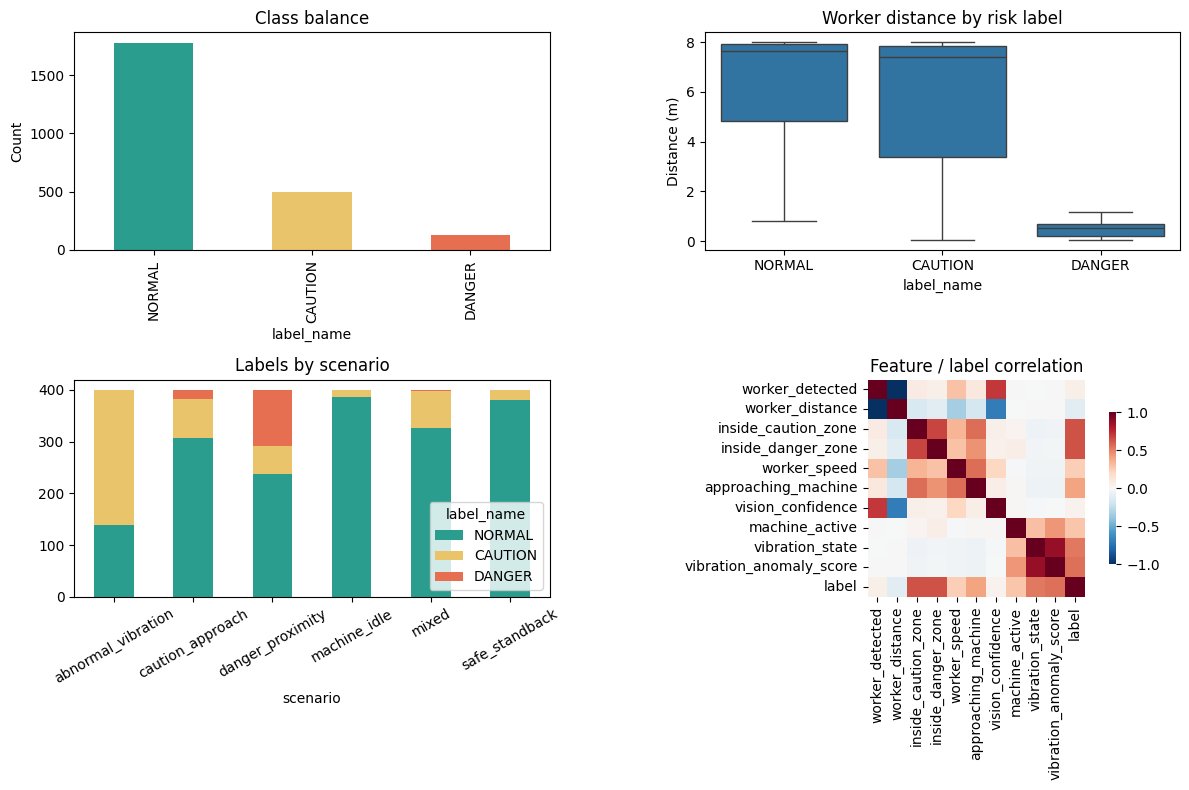

Saved: /content/drive/MyDrive/SAMS/results/fusion/eda/fusion_eda_overview.png


In [6]:
# --- EDA --------------------------------------------------------------------
eda_dir = RESULTS_DIR / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

print("=== Overview ===")
print(fusion_df[FEATURE_COLS + ["label_name", "scenario", "trial_id"]].describe(include="all").T.head(20))
print("\nMissing values:", int(fusion_df[FEATURE_COLS].isna().sum().sum()))
print("Trials:", fusion_df["trial_id"].nunique())
print("Scenarios:", fusion_df["scenario"].value_counts().to_dict())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

fusion_df["label_name"].value_counts().reindex(CLASS_NAMES).plot(
    kind="bar", ax=axes[0, 0], color=["#2a9d8f", "#e9c46a", "#e76f51"]
)
axes[0, 0].set_title("Class balance")
axes[0, 0].set_ylabel("Count")

sns.boxplot(
    data=fusion_df[fusion_df["worker_detected"] == 1],
    x="label_name", y="worker_distance", order=CLASS_NAMES, ax=axes[0, 1],
)
axes[0, 1].set_title("Worker distance by risk label")
axes[0, 1].set_ylabel("Distance (m)")

pd.crosstab(fusion_df["scenario"], fusion_df["label_name"]).reindex(columns=CLASS_NAMES).plot(
    kind="bar", stacked=True, ax=axes[1, 0], color=["#2a9d8f", "#e9c46a", "#e76f51"]
)
axes[1, 0].set_title("Labels by scenario")
axes[1, 0].tick_params(axis="x", rotation=30)

corr = fusion_df[FEATURE_COLS + ["label"]].corr(numeric_only=True)
sns.heatmap(corr, ax=axes[1, 1], cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7})
axes[1, 1].set_title("Feature / label correlation")

plt.tight_layout()
fig_path = eda_dir / "fusion_eda_overview.png"
plt.savefig(fig_path, dpi=140, bbox_inches="tight")
plt.show()
print("Saved:", fig_path)


## 3. Trial-holdout split (prevent leakage)

Samples from the **same experimental trial** stay together.
Split target ≈ **70% train / 15% val / 15% test** by trial count.

Trials are **stratified by scenario** so DANGER-heavy scenarios (e.g. `danger_proximity`)
appear in every split — avoiding empty DANGER folds.


In [7]:
# --- Trial-holdout split (scenario-stratified) ------------------------------
# Keep whole trials together, but stratify by scenario so rare DANGER-heavy
# scenarios (e.g. danger_proximity) are represented in train / val / test.

trial_meta = (
    fusion_df.groupby("trial_id", as_index=False)
    .agg(scenario=("scenario", "first"), n_danger=("label", lambda s: int((s == 2).sum())))
)

train_trials, val_trials, test_trials = set(), set(), set()
for scenario, grp in trial_meta.groupby("scenario"):
    ids = grp["trial_id"].to_numpy()
    ids = rng.permutation(ids)
    n = len(ids)
    n_test = max(1, int(round(0.15 * n))) if n >= 3 else (1 if n >= 2 else 0)
    n_val = max(1, int(round(0.15 * n))) if n >= 3 else 0
    # Ensure remaining go to train
    while n_test + n_val >= n and n_val > 0:
        n_val -= 1
    while n_test + n_val >= n and n_test > 0:
        n_test -= 1
    test_ids = set(ids[:n_test].tolist())
    val_ids = set(ids[n_test:n_test + n_val].tolist())
    train_ids = set(ids[n_test + n_val:].tolist())
    test_trials |= test_ids
    val_trials |= val_ids
    train_trials |= train_ids

print(f"Trials — train={len(train_trials)} val={len(val_trials)} test={len(test_trials)}")


def split_mask(trials: set) -> np.ndarray:
    return fusion_df["trial_id"].isin(trials).to_numpy()


train_m = split_mask(train_trials)
val_m = split_mask(val_trials)
test_m = split_mask(test_trials)

X_train = fusion_df.loc[train_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_train = fusion_df.loc[train_m, "label"].to_numpy(dtype=np.int64)
X_val = fusion_df.loc[val_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_val = fusion_df.loc[val_m, "label"].to_numpy(dtype=np.int64)
X_test = fusion_df.loc[test_m, FEATURE_COLS].to_numpy(dtype=np.float32)
y_test = fusion_df.loc[test_m, "label"].to_numpy(dtype=np.int64)

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    counts = {CLASS_NAMES[i]: int((yy == i).sum()) for i in range(3)}
    print(f"{name:5s}: n={len(yy):5d} | {counts}")

# Soft warning if a split still lacks DANGER (possible with tiny trial counts)
for name, yy in [("val", y_val), ("test", y_test)]:
    if (yy == 2).sum() == 0:
        print(f"WARNING: {name} has 0 DANGER samples — DANGER metrics will be 0/undefined for that split.")


Trials — train=36 val=12 test=12
train: n= 1440 | {'NORMAL': 1054, 'CAUTION': 302, 'DANGER': 84}
val  : n=  480 | {'NORMAL': 363, 'CAUTION': 97, 'DANGER': 20}
test : n=  480 | {'NORMAL': 362, 'CAUTION': 94, 'DANGER': 24}


## 4. Shared evaluation / save utilities

In [8]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    # False-alarm rate among true NORMAL: predicted CAUTION or DANGER
    normal_mask = y_true == 0
    false_alarm_rate = float(((y_pred[normal_mask] != 0).sum() / max(1, normal_mask.sum())))
    # DANGER recall (missed dangers are critical)
    per_p = precision_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    per_r = recall_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    per_f = f1_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    danger_precision = float(per_p[2])
    danger_recall = float(per_r[2])
    danger_f1 = float(per_f[2])
    missed_dangers = int(((y_true == 2) & (y_pred != 2)).sum())

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "danger_precision": danger_precision,
        "danger_recall": danger_recall,
        "danger_f1": danger_f1,
        "missed_dangers": missed_dangers,
        "false_alarm_rate": false_alarm_rate,
        "confusion_matrix": cm.tolist(),
        "classification_report": classification_report(
            y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=4, zero_division=0
        ),
    }


def print_metrics(tag: str, metrics: Dict[str, Any]) -> None:
    print(f"\n=== {tag} ===")
    print(f"Accuracy:          {metrics['accuracy']:.4f}")
    print(f"Precision (macro): {metrics['precision_macro']:.4f}")
    print(f"Recall (macro):    {metrics['recall_macro']:.4f}")
    print(f"F1 (macro):        {metrics['f1_macro']:.4f}")
    print(f"DANGER recall:     {metrics['danger_recall']:.4f}  ← primary safety metric")
    print(f"DANGER precision:  {metrics['danger_precision']:.4f}")
    print(f"Missed DANGER:     {metrics['missed_dangers']}")
    print(f"False-alarm rate:  {metrics['false_alarm_rate']:.4f}")
    print(metrics["classification_report"])


def measure_latency_ms(model, X: np.ndarray, n_runs: int = 200) -> Dict[str, float]:
    """Median / p95 single-row inference latency in milliseconds."""
    # Warmup
    _ = model.predict(X[:1])
    times = []
    for i in range(n_runs):
        row = X[i % len(X): i % len(X) + 1]
        t0 = time.perf_counter()
        _ = model.predict(row)
        times.append((time.perf_counter() - t0) * 1000.0)
    arr = np.asarray(times)
    return {
        "latency_ms_median": float(np.median(arr)),
        "latency_ms_p95": float(np.percentile(arr, 95)),
        "latency_ms_mean": float(arr.mean()),
    }


def _to_jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return obj


def save_experiment(
    experiment_id: str,
    approach: str,
    model_obj: Any,
    metrics: Dict[str, Any],
    extra_meta: Optional[Dict] = None,
) -> Path:
    out_dir = MODELS_DIR / experiment_id
    out_dir.mkdir(parents=True, exist_ok=True)

    model_path = out_dir / "model.joblib"
    joblib.dump(model_obj, model_path)

    meta = {
        "experiment_id": experiment_id,
        "approach": approach,
        "task": "fusion_risk_classification",
        "dataset": DATA_SOURCE,
        "class_names": CLASS_NAMES,
        "label_to_idx": LABEL_TO_IDX,
        "feature_cols": FEATURE_COLS,
        "zones_m": {"caution": CAUTION_ZONE_M, "danger": DANGER_ZONE_M},
        "split": {
            "strategy": "trial_holdout",
            "train_trials": sorted(train_trials),
            "val_trials": sorted(val_trials),
            "test_trials": sorted(test_trials),
            "fractions": "≈70/15/15",
        },
        "test_metrics": {k: v for k, v in metrics.items() if k != "classification_report"},
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "model_path": str(model_path),
        "model_kind": "sklearn",
    }
    if extra_meta:
        meta.update(extra_meta)

    meta_path = out_dir / "metadata.json"
    report_path = out_dir / "classification_report.txt"
    cm_path = out_dir / "confusion_matrix.png"

    with open(meta_path, "w") as f:
        json.dump(_to_jsonable(meta), f, indent=2)
    with open(report_path, "w") as f:
        f.write(metrics["classification_report"])

    cm = np.array(metrics["confusion_matrix"])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"Confusion — {experiment_id}")
    plt.tight_layout()
    plt.savefig(cm_path, dpi=140)
    plt.show()

    ledger_path = RESULTS_DIR / "fusion_experiment_ledger.csv"
    row = {
        "experiment_id": experiment_id,
        "approach": approach,
        "accuracy": metrics["accuracy"],
        "precision_macro": metrics["precision_macro"],
        "recall_macro": metrics["recall_macro"],
        "f1_macro": metrics["f1_macro"],
        "f1_weighted": metrics["f1_weighted"],
        "danger_recall": metrics["danger_recall"],
        "danger_precision": metrics["danger_precision"],
        "danger_f1": metrics["danger_f1"],
        "missed_dangers": metrics["missed_dangers"],
        "false_alarm_rate": metrics["false_alarm_rate"],
        "model_path": str(model_path),
        "metadata_path": str(meta_path),
        "timestamp_utc": meta["timestamp_utc"],
    }
    if extra_meta:
        for k in ("latency_ms_median", "latency_ms_p95", "val_danger_recall"):
            if k in extra_meta:
                row[k] = extra_meta[k]

    ledger = pd.DataFrame([row])
    if ledger_path.exists():
        prev = pd.read_csv(ledger_path)
        prev = prev[prev["experiment_id"] != experiment_id]
        ledger = pd.concat([prev, ledger], ignore_index=True)
    ledger.to_csv(ledger_path, index=False)

    print(f"[SAVE] model → {model_path}")
    print(f"[SAVE] metadata → {meta_path}")
    print(f"[SAVE] ledger → {ledger_path}")
    return out_dir


EXPERIMENT_RESULTS: List[Dict[str, Any]] = []
print("Utilities ready.")


Utilities ready.


## 5. Experiments

### Experiment 1 — Random Forest

EXPERIMENT: fusion_exp01_random_forest
APPROACH:   Classical baseline — Random Forest on fusion features

=== VAL ===
Accuracy:          0.9854
Precision (macro): 0.9263
Recall (macro):    0.9835
F1 (macro):        0.9512
DANGER recall:     1.0000  ← primary safety metric
DANGER precision:  0.8000
Missed DANGER:     0
False-alarm rate:  0.0083
              precision    recall  f1-score   support

      NORMAL     1.0000    0.9917    0.9959       363
     CAUTION     0.9789    0.9588    0.9688        97
      DANGER     0.8000    1.0000    0.8889        20

    accuracy                         0.9854       480
   macro avg     0.9263    0.9835    0.9512       480
weighted avg     0.9874    0.9854    0.9859       480


=== TEST ===
Accuracy:          1.0000
Precision (macro): 1.0000
Recall (macro):    1.0000
F1 (macro):        1.0000
DANGER recall:     1.0000  ← primary safety metric
DANGER precision:  1.0000
Missed DANGER:     0
False-alarm rate:  0.0000
              precision    reca

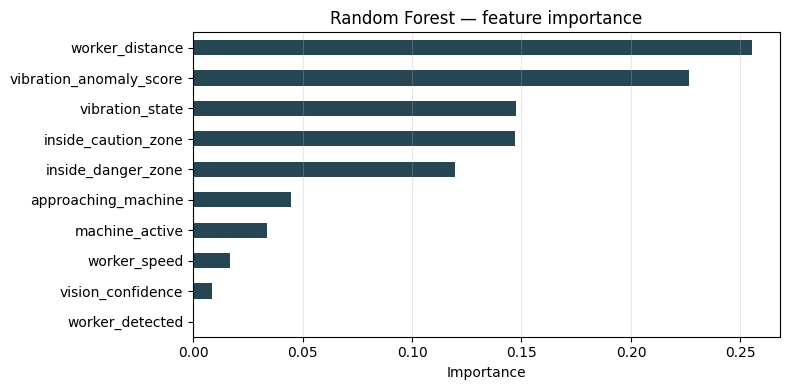

worker_distance            0.255316
vibration_anomaly_score    0.226716
vibration_state            0.147464
inside_caution_zone        0.146856
inside_danger_zone         0.119526
approaching_machine        0.044592
machine_active             0.033966
worker_speed               0.017056
vision_confidence          0.008444
worker_detected            0.000064


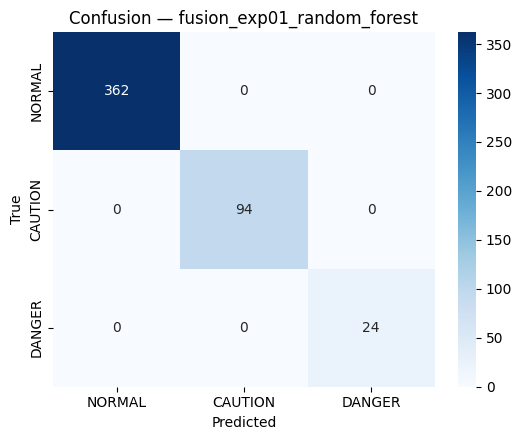

[SAVE] model → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp01_random_forest/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp01_random_forest/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/fusion/fusion_experiment_ledger.csv
GC done.


In [9]:
exp_id = "fusion_exp01_random_forest"
approach = "Classical baseline — Random Forest on fusion features"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

val_pred = rf.predict(X_val)
test_pred = rf.predict(X_test)
val_metrics = compute_metrics(y_val, val_pred)
test_metrics = compute_metrics(y_test, test_pred)
latency = measure_latency_ms(rf, X_test)
elapsed = time.time() - t0

print_metrics("VAL", val_metrics)
print_metrics("TEST", test_metrics)
print(f"Latency median={latency['latency_ms_median']:.3f} ms | p95={latency['latency_ms_p95']:.3f} ms")
print(f"Elapsed: {elapsed:.1f}s")

# Feature importance
imp = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
imp.plot(kind="barh", ax=ax, color="#264653")
ax.invert_yaxis()
ax.set_xlabel("Importance")
ax.set_title("Random Forest — feature importance")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
imp_path = MODELS_DIR / exp_id
imp_path.mkdir(parents=True, exist_ok=True)
plt.savefig(imp_path / "feature_importance.png", dpi=140)
plt.show()
print(imp.to_string())

save_experiment(
    exp_id, approach, rf, test_metrics,
    extra_meta={
        "model": "RandomForestClassifier",
        "elapsed_sec": elapsed,
        "val_danger_recall": val_metrics["danger_recall"],
        "val_f1_macro": val_metrics["f1_macro"],
        "feature_importance": imp.to_dict(),
        **latency,
        "hyperparams": {
            "n_estimators": 300,
            "class_weight": "balanced",
            "min_samples_leaf": 2,
            "random_state": SEED,
        },
    },
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics, "latency": latency})

del rf
gc.collect()
print("GC done.")


### Experiment 2 — XGBoost

EXPERIMENT: fusion_exp02_xgboost
APPROACH:   Boosted trees — XGBoost on fusion features

=== VAL ===
Accuracy:          0.9917
Precision (macro): 0.9628
Recall (macro):    0.9913
F1 (macro):        0.9763
DANGER recall:     1.0000  ← primary safety metric
DANGER precision:  0.9091
Missed DANGER:     0
False-alarm rate:  0.0055
              precision    recall  f1-score   support

      NORMAL     1.0000    0.9945    0.9972       363
     CAUTION     0.9794    0.9794    0.9794        97
      DANGER     0.9091    1.0000    0.9524        20

    accuracy                         0.9917       480
   macro avg     0.9628    0.9913    0.9763       480
weighted avg     0.9920    0.9917    0.9918       480


=== TEST ===
Accuracy:          1.0000
Precision (macro): 1.0000
Recall (macro):    1.0000
F1 (macro):        1.0000
DANGER recall:     1.0000  ← primary safety metric
DANGER precision:  1.0000
Missed DANGER:     0
False-alarm rate:  0.0000
              precision    recall  f1-score   su

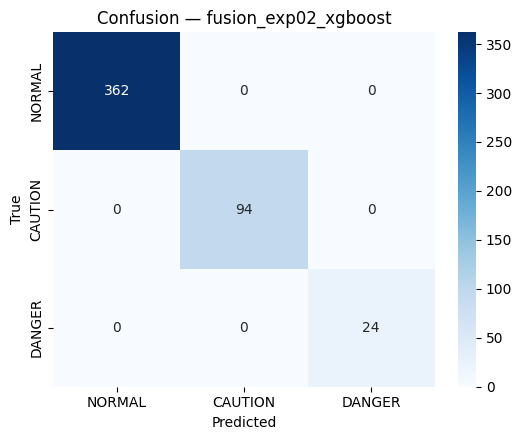

[SAVE] model → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp02_xgboost/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp02_xgboost/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/fusion/fusion_experiment_ledger.csv
GC done.


In [10]:
# XGBoost — works out of the box on Colab/Linux.
# On some macOS local envs, libomp may be missing (`brew install libomp`).
try:
    from xgboost import XGBClassifier
    _XGB_OK = True
except Exception as e:
    _XGB_OK = False
    print("Skipping XGBoost experiment (import failed):", e)
    print("On Colab this normally works. Local macOS fix: brew install libomp")

if _XGB_OK:
    exp_id = "fusion_exp02_xgboost"
    approach = "Boosted trees — XGBoost on fusion features"
    print("EXPERIMENT:", exp_id)
    print("APPROACH:  ", approach)

    t0 = time.time()
    # Multiclass imbalance via sample weights (scale_pos_weight is binary-only)
    counts = np.bincount(y_train, minlength=3).astype(np.float64)
    class_w = counts.sum() / (3.0 * np.clip(counts, 1, None))
    sample_w = class_w[y_train]

    xgb = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=SEED,
        n_jobs=-1,
        verbosity=0,
    )
    fit_kwargs = {"sample_weight": sample_w}
    try:
        xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False, **fit_kwargs)
    except TypeError:
        xgb.fit(X_train, y_train, **fit_kwargs)

    val_pred = xgb.predict(X_val)
    test_pred = xgb.predict(X_test)
    val_metrics = compute_metrics(y_val, val_pred)
    test_metrics = compute_metrics(y_test, test_pred)
    latency = measure_latency_ms(xgb, X_test)
    elapsed = time.time() - t0

    print_metrics("VAL", val_metrics)
    print_metrics("TEST", test_metrics)
    print(f"Latency median={latency['latency_ms_median']:.3f} ms | p95={latency['latency_ms_p95']:.3f} ms")
    print(f"Elapsed: {elapsed:.1f}s")

    save_experiment(
        exp_id, approach, xgb, test_metrics,
        extra_meta={
            "model": "XGBClassifier",
            "elapsed_sec": elapsed,
            "val_danger_recall": val_metrics["danger_recall"],
            "val_f1_macro": val_metrics["f1_macro"],
            **latency,
            "hyperparams": {
                "n_estimators": 300,
                "max_depth": 5,
                "learning_rate": 0.08,
                "objective": "multi:softprob",
            },
        },
    )
    EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics, "latency": latency})

    del xgb
    gc.collect()
    print("GC done.")


### Experiment 3 — SVM RBF (scaled features)

EXPERIMENT: fusion_exp03_svm_rbf
APPROACH:   Margin classifier — SVM RBF on scaled fusion features

=== VAL ===
Accuracy:          0.9833
Precision (macro): 0.9746
Recall (macro):    0.9454
F1 (macro):        0.9575
DANGER recall:     0.8500  ← primary safety metric
DANGER precision:  1.0000
Missed DANGER:     3
False-alarm rate:  0.0138
              precision    recall  f1-score   support

      NORMAL     1.0000    0.9862    0.9931       363
     CAUTION     0.9238    1.0000    0.9604        97
      DANGER     1.0000    0.8500    0.9189        20

    accuracy                         0.9833       480
   macro avg     0.9746    0.9454    0.9575       480
weighted avg     0.9846    0.9833    0.9834       480


=== TEST ===
Accuracy:          0.9729
Precision (macro): 0.9459
Recall (macro):    0.9050
F1 (macro):        0.9210
DANGER recall:     0.7500  ← primary safety metric
DANGER precision:  0.9474
Missed DANGER:     6
False-alarm rate:  0.0138
              precision    recall  f1

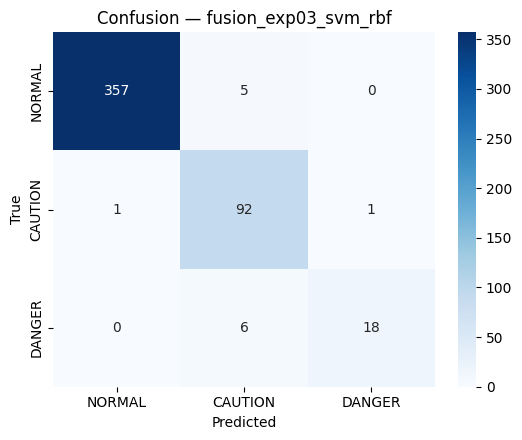

[SAVE] model → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp03_svm_rbf/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp03_svm_rbf/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/fusion/fusion_experiment_ledger.csv
GC done.


In [11]:
exp_id = "fusion_exp03_svm_rbf"
approach = "Margin classifier — SVM RBF on scaled fusion features"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

t0 = time.time()
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(
        kernel="rbf",
        C=10.0,
        gamma="scale",
        class_weight="balanced",
        random_state=SEED,
    )),
])
svm.fit(X_train, y_train)

val_pred = svm.predict(X_val)
test_pred = svm.predict(X_test)
val_metrics = compute_metrics(y_val, val_pred)
test_metrics = compute_metrics(y_test, test_pred)
latency = measure_latency_ms(svm, X_test)
elapsed = time.time() - t0

print_metrics("VAL", val_metrics)
print_metrics("TEST", test_metrics)
print(f"Latency median={latency['latency_ms_median']:.3f} ms | p95={latency['latency_ms_p95']:.3f} ms")
print(f"Elapsed: {elapsed:.1f}s")

save_experiment(
    exp_id, approach, svm, test_metrics,
    extra_meta={
        "model": "Pipeline(StandardScaler, SVC(rbf))",
        "elapsed_sec": elapsed,
        "val_danger_recall": val_metrics["danger_recall"],
        "val_f1_macro": val_metrics["f1_macro"],
        **latency,
        "hyperparams": {"C": 10.0, "gamma": "scale", "class_weight": "balanced"},
    },
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics, "latency": latency})

del svm
gc.collect()
print("GC done.")


### Experiment 4 — Multilayer Perceptron (MLP)

EXPERIMENT: fusion_exp04_mlp
APPROACH:   Neural net — MLP on scaled fusion features

=== VAL ===
Accuracy:          0.9771
Precision (macro): 0.9619
Recall (macro):    0.9250
F1 (macro):        0.9425
DANGER recall:     0.8500  ← primary safety metric
DANGER precision:  0.9444
Missed DANGER:     3
False-alarm rate:  0.0028
              precision    recall  f1-score   support

      NORMAL     0.9837    0.9972    0.9904       363
     CAUTION     0.9574    0.9278    0.9424        97
      DANGER     0.9444    0.8500    0.8947        20

    accuracy                         0.9771       480
   macro avg     0.9619    0.9250    0.9425       480
weighted avg     0.9768    0.9771    0.9767       480


=== TEST ===
Accuracy:          0.9833
Precision (macro): 0.9739
Recall (macro):    0.9148
F1 (macro):        0.9379
DANGER recall:     0.7500  ← primary safety metric
DANGER precision:  1.0000
Missed DANGER:     6
False-alarm rate:  0.0055
              precision    recall  f1-score   suppor

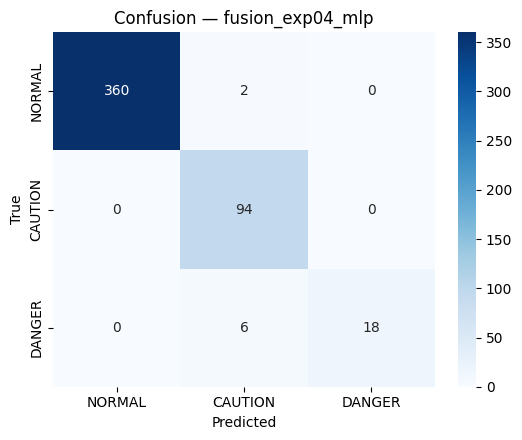

[SAVE] model → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp04_mlp/model.joblib
[SAVE] metadata → /content/drive/MyDrive/SAMS/models/fusion/fusion_exp04_mlp/metadata.json
[SAVE] ledger → /content/drive/MyDrive/SAMS/results/fusion/fusion_experiment_ledger.csv
GC done.


In [12]:
exp_id = "fusion_exp04_mlp"
approach = "Neural net — MLP on scaled fusion features"
print("EXPERIMENT:", exp_id)
print("APPROACH:  ", approach)

t0 = time.time()
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=400,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=SEED,
    )),
])
mlp.fit(X_train, y_train)

val_pred = mlp.predict(X_val)
test_pred = mlp.predict(X_test)
val_metrics = compute_metrics(y_val, val_pred)
test_metrics = compute_metrics(y_test, test_pred)
latency = measure_latency_ms(mlp, X_test)
elapsed = time.time() - t0

print_metrics("VAL", val_metrics)
print_metrics("TEST", test_metrics)
print(f"Latency median={latency['latency_ms_median']:.3f} ms | p95={latency['latency_ms_p95']:.3f} ms")
print(f"Elapsed: {elapsed:.1f}s")

save_experiment(
    exp_id, approach, mlp, test_metrics,
    extra_meta={
        "model": "Pipeline(StandardScaler, MLPClassifier)",
        "elapsed_sec": elapsed,
        "val_danger_recall": val_metrics["danger_recall"],
        "val_f1_macro": val_metrics["f1_macro"],
        **latency,
        "hyperparams": {
            "hidden_layer_sizes": [64, 32],
            "max_iter": 400,
            "early_stopping": True,
        },
    },
)
EXPERIMENT_RESULTS.append({"experiment_id": exp_id, "approach": approach, "test_metrics": test_metrics, "latency": latency})

del mlp
gc.collect()
print("GC done.")


## 6. Comparison — pick the SAMS fusion backbone

Note: with **rule-guided synthetic** labels, scores can look near-perfect because
features and labels share the same safety rules. Real synchronized experiment logs
will give a more realistic performance picture — **DANGER recall** remains the priority.


In [13]:
ledger_path = RESULTS_DIR / "fusion_experiment_ledger.csv"
if ledger_path.exists():
    comparison_df = pd.read_csv(ledger_path)
else:
    comparison_df = pd.DataFrame([
        {
            "experiment_id": r["experiment_id"],
            "approach": r["approach"],
            "accuracy": r["test_metrics"]["accuracy"],
            "precision_macro": r["test_metrics"]["precision_macro"],
            "recall_macro": r["test_metrics"]["recall_macro"],
            "f1_macro": r["test_metrics"]["f1_macro"],
            "f1_weighted": r["test_metrics"]["f1_weighted"],
            "danger_recall": r["test_metrics"]["danger_recall"],
            "danger_precision": r["test_metrics"]["danger_precision"],
            "danger_f1": r["test_metrics"]["danger_f1"],
            "missed_dangers": r["test_metrics"]["missed_dangers"],
            "false_alarm_rate": r["test_metrics"]["false_alarm_rate"],
            "latency_ms_median": r["latency"]["latency_ms_median"],
        }
        for r in EXPERIMENT_RESULTS
    ])

# Rank primarily by DANGER recall, then F1-macro, then low false-alarm rate
comparison_df = comparison_df.sort_values(
    by=["danger_recall", "f1_macro", "false_alarm_rate"],
    ascending=[False, False, True],
).reset_index(drop=True)

comparison_path = RESULTS_DIR / "fusion_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("=== SAMS Fusion Model Comparison (sorted by DANGER recall → F1-macro) ===")
display_cols = [
    "experiment_id", "approach", "accuracy", "f1_macro",
    "danger_recall", "danger_precision", "missed_dangers",
    "false_alarm_rate", "latency_ms_median",
]
cols = [c for c in display_cols if c in comparison_df.columns]
print(comparison_df[cols].to_string(index=False))
print("\nSaved:", comparison_path)

best = comparison_df.iloc[0]
print("\n★ Best experiment:", best["experiment_id"])
print("  Approach:", best["approach"])
print("  DANGER recall:", round(float(best["danger_recall"]), 4))
print("  F1-macro:", round(float(best["f1_macro"]), 4))
print("  False-alarm rate:", round(float(best["false_alarm_rate"]), 4))


=== SAMS Fusion Model Comparison (sorted by DANGER recall → F1-macro) ===
             experiment_id                                              approach  accuracy  f1_macro  danger_recall  danger_precision  missed_dangers  false_alarm_rate  latency_ms_median
fusion_exp01_random_forest Classical baseline — Random Forest on fusion features  1.000000  1.000000           1.00          1.000000               0          0.000000          78.137212
      fusion_exp02_xgboost            Boosted trees — XGBoost on fusion features  1.000000  1.000000           1.00          1.000000               0          0.000000           0.606508
          fusion_exp04_mlp            Neural net — MLP on scaled fusion features  0.983333  0.937852           0.75          1.000000               6          0.005525           0.671514
      fusion_exp03_svm_rbf Margin classifier — SVM RBF on scaled fusion features  0.972917  0.920962           0.75          0.947368               6          0.013812           

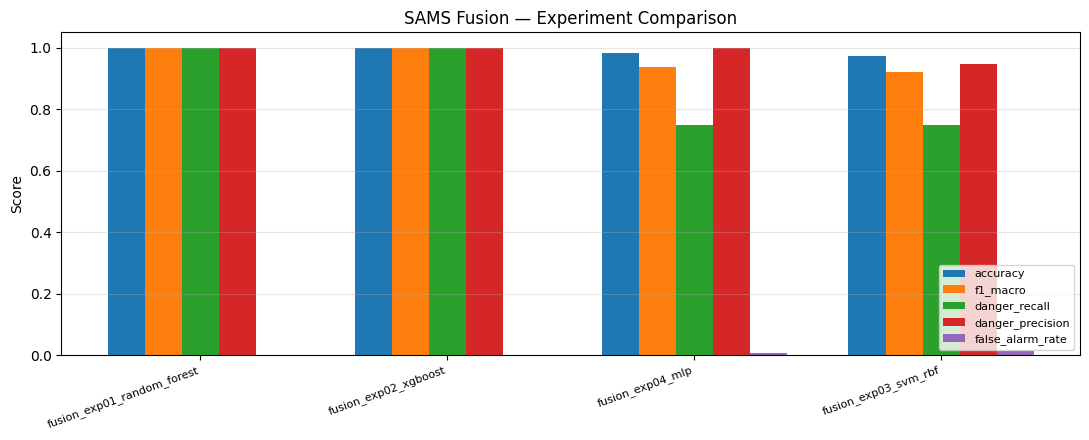

Saved chart: /content/drive/MyDrive/SAMS/results/fusion/fusion_comparison_bars.png


In [14]:
plot_df = comparison_df.copy()
metrics = [c for c in [
    "accuracy", "f1_macro", "danger_recall", "danger_precision", "false_alarm_rate"
] if c in plot_df.columns]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(plot_df))
width = 0.15
for i, m in enumerate(metrics):
    ax.bar(x + i * width, plot_df[m], width, label=m)
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(plot_df["experiment_id"], rotation=20, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("SAMS Fusion — Experiment Comparison")
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig_path = RESULTS_DIR / "fusion_comparison_bars.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print("Saved chart:", fig_path)


In [15]:
summary = {
    "task": "fusion_risk_classification",
    "dataset": DATA_SOURCE,
    "num_experiments": int(len(comparison_df)),
    "primary_metric": "danger_recall",
    "secondary_metric": "f1_macro",
    "best_experiment_id": str(best["experiment_id"]),
    "best_approach": str(best["approach"]),
    "best_metrics": {
        "accuracy": float(best["accuracy"]),
        "f1_macro": float(best["f1_macro"]),
        "danger_recall": float(best["danger_recall"]),
        "danger_precision": float(best.get("danger_precision", float("nan"))),
        "false_alarm_rate": float(best["false_alarm_rate"]),
    },
    "class_names": CLASS_NAMES,
    "feature_cols": FEATURE_COLS,
    "zones_m": {"caution": CAUTION_ZONE_M, "danger": DANGER_ZONE_M},
    "models_dir": str(MODELS_DIR),
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}
summary_path = RESULTS_DIR / "fusion_comparison_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)
print("Summary:", summary_path)
print(json.dumps(summary["best_metrics"], indent=2))

# Promote best model to a stable deployment path
best_src = MODELS_DIR / str(best["experiment_id"])
best_dst = MODELS_DIR / "best_fusion_model"
best_dst.mkdir(parents=True, exist_ok=True)
for name in ("model.joblib", "metadata.json", "classification_report.txt", "confusion_matrix.png"):
    src_f = best_src / name
    if src_f.exists():
        import shutil
        shutil.copy2(src_f, best_dst / name)
# Also copy feature importance when RF wins
fi = best_src / "feature_importance.png"
if fi.exists():
    import shutil
    shutil.copy2(fi, best_dst / "feature_importance.png")

with open(best_dst / "SELECTED.json", "w") as f:
    json.dump(
        {
            "selected_experiment_id": str(best["experiment_id"]),
            "selection_rule": "max danger_recall, then f1_macro, then min false_alarm_rate",
            "metrics": summary["best_metrics"],
        },
        f,
        indent=2,
    )
print("Promoted best model →", best_dst.resolve())


Summary: /content/drive/MyDrive/SAMS/results/fusion/fusion_comparison_summary.json
{
  "accuracy": 1.0,
  "f1_macro": 1.0,
  "danger_recall": 1.0,
  "danger_precision": 1.0,
  "false_alarm_rate": 0.0
}
Promoted best model → /content/drive/MyDrive/SAMS/models/fusion/best_fusion_model


## 7. Inference demo — fused observation → risk class

Load the best saved model and classify a few example SAMS situations
(matching the Fusion Model design doc):

| Scene | Expected |
|-------|----------|
| Distance 4.0 m, vib normal | NORMAL |
| Distance 1.5 m, caution zone, approaching | CAUTION |
| Distance 0.4 m, danger zone | DANGER |
| Distance 3.1 m, abnormal vibration | CAUTION |


In [16]:
# --- Load best model & predict example scenes --------------------------------
best_id = str(best["experiment_id"])
best_model = joblib.load(MODELS_DIR / best_id / "model.joblib")

examples = pd.DataFrame([
    {  # NORMAL — far from machine, vib normal
        "worker_detected": 1, "worker_distance": 4.0,
        "inside_caution_zone": 0, "inside_danger_zone": 0,
        "worker_speed": 0.2, "approaching_machine": 0,
        "vision_confidence": 0.92, "machine_active": 1,
        "vibration_state": 0, "vibration_anomaly_score": 0.12,
        "scene": "Stand-back + machine on + vib normal",
    },
    {  # CAUTION — caution zone, approaching
        "worker_detected": 1, "worker_distance": 1.5,
        "inside_caution_zone": 1, "inside_danger_zone": 0,
        "worker_speed": 0.7, "approaching_machine": 1,
        "vision_confidence": 0.90, "machine_active": 1,
        "vibration_state": 0, "vibration_anomaly_score": 0.18,
        "scene": "Caution zone + approaching",
    },
    {  # DANGER — inside danger zone
        "worker_detected": 1, "worker_distance": 0.4,
        "inside_caution_zone": 1, "inside_danger_zone": 1,
        "worker_speed": 0.5, "approaching_machine": 1,
        "vision_confidence": 0.94, "machine_active": 1,
        "vibration_state": 0, "vibration_anomaly_score": 0.20,
        "scene": "Danger zone proximity",
    },
    {  # CAUTION — far but abnormal vibration
        "worker_detected": 1, "worker_distance": 3.1,
        "inside_caution_zone": 0, "inside_danger_zone": 0,
        "worker_speed": 0.1, "approaching_machine": 0,
        "vision_confidence": 0.89, "machine_active": 1,
        "vibration_state": 1, "vibration_anomaly_score": 0.78,
        "scene": "Abnormal vibration (worker clear)",
    },
])

X_ex = examples[FEATURE_COLS].to_numpy(dtype=np.float32)
preds = best_model.predict(X_ex)
examples["prediction"] = [IDX_TO_LABEL[int(p)] for p in preds]

# Probabilities when available
if hasattr(best_model, "predict_proba"):
    proba = best_model.predict_proba(X_ex)
    for i, name in enumerate(CLASS_NAMES):
        examples[f"p_{name}"] = proba[:, i]

print(f"Loaded: {best_id}")
display(examples[["scene", "worker_distance", "inside_danger_zone", "approaching_machine",
                  "machine_active", "vibration_state", "prediction"]
                 + [c for c in examples.columns if c.startswith("p_")]])


Loaded: fusion_exp01_random_forest


,scene,worker_distance,inside_danger_zone,approaching_machine,machine_active,vibration_state,prediction,p_NORMAL,p_CAUTION,p_DANGER
0,Stand-back + machine on + vib normal,4.0,0,0,1,0,NORMAL,1.000000,0.000000,0.000000
1,Caution zone + approaching,1.5,0,1,1,0,CAUTION,0.027915,0.951455,0.020631
2,Danger zone proximity,0.4,1,1,1,0,DANGER,0.000000,0.008291,0.991709
3,Abnormal vibration (worker clear),3.1,0,0,1,1,CAUTION,0.016187,0.983813,0.000000


In [17]:
print("Done. Fusion risk-classification experiment suite finished.")
print("Models:", MODELS_DIR.resolve())
print("Results:", RESULTS_DIR.resolve())
print("Dataset:", (DATA_DIR / "fusion_features_labeled.csv").resolve())
print()
print("SAMS ML pipeline is now complete:")
print("  1. Vision Model")
print("  2. Vibration Model")
print("  3. Fusion Classification Model  ← this notebook")


Done. Fusion risk-classification experiment suite finished.
Models: /content/drive/MyDrive/SAMS/models/fusion
Results: /content/drive/MyDrive/SAMS/results/fusion
Dataset: /content/drive/MyDrive/SAMS/datasets/fusion/fusion_features_labeled.csv

SAMS ML pipeline is now complete:
  1. Vision Model
  2. Vibration Model
  3. Fusion Classification Model  ← this notebook
